In [ ]:
{
 "cells": [],
 "metadata": {},
 "nbformat": 4,
 "nbformat_minor": 5
}

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.linalg import eigvals, svdvals
from scipy.sparse import diags

In [3]:
# ---------------------------------------------------------
# Figure output directory
# ---------------------------------------------------------

FIGURE_DIR = Path("../results/figures/matrix_analysis")

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Figures will be saved to:")
print(FIGURE_DIR.resolve())

Figures will be saved to:
C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\figures\matrix_analysis


In [4]:
# ---------------------------------------------------------
# Numerical-data output directory
# ---------------------------------------------------------

TABLE_DIR = Path("../results/tables/matrix_analysis")

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Numerical data will be saved to:")
print(TABLE_DIR.resolve())

Numerical data will be saved to:
C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\matrix_analysis


In [5]:
# ---------------------------------------------------------
# Small velocity grid for quantum-ready matrix analysis
# ---------------------------------------------------------

k = 0.5

v_min = -6.0
v_max = 6.0

Nv = 32

v = np.linspace(v_min, v_max, Nv)
dv = (v_max - v_min) / (Nv - 1)

print("k       =", k)
print("Nv      =", Nv)
print("v_min   =", v_min)
print("v_max   =", v_max)
print("dv      =", dv)

k       = 0.5
Nv      = 32
v_min   = -6.0
v_max   = 6.0
dv      = 0.3870967741935484


In [6]:
# ---------------------------------------------------------
# Maxwellian equilibrium
# ---------------------------------------------------------

f0 = (1.0 / np.sqrt(2.0 * np.pi)) * np.exp(-v**2 / 2.0)

# Analytical derivative:
# df0/dv = -v * f0
df0_dv = -v * f0

print("f0 shape     :", f0.shape)
print("df0/dv shape :", df0_dv.shape)
print("f0 integral  :", np.trapezoid(f0, v))

f0 shape     : (32,)
df0/dv shape : (32,)
f0 integral  : 0.9999999971843628


In [7]:
# ---------------------------------------------------------
# Trapezoidal quadrature weights
# ---------------------------------------------------------

w = np.full(Nv, dv)

w[0] *= 0.5
w[-1] *= 0.5

print("First weight :", w[0])
print("Interior     :", w[1])
print("Last weight  :", w[-1])
print("Weight sum   :", np.sum(w))

First weight : 0.1935483870967742
Interior     : 0.3870967741935484
Last weight  : 0.1935483870967742
Weight sum   : 12.0


In [8]:
# ---------------------------------------------------------
# Linearized Vlasov-Poisson matrix
# ---------------------------------------------------------

V = np.diag(v)

M_k = (
    -1j * k * V
    + (1.0 / (1j * k)) * np.outer(df0_dv, w)
)

print("M_k shape:", M_k.shape)
print("M_k dtype:", M_k.dtype)

M_k shape: (32, 32)
M_k dtype: complex128


In [9]:
# ---------------------------------------------------------
# Inspect matrix structure
# ---------------------------------------------------------

np.set_printoptions(precision=3, suppress=True)

print("Top-left 6x6 block of M_k:\n")
print(M_k[:6, :6])

Top-left 6x6 block of M_k:

[[0.+3.j    0.-0.j    0.-0.j    0.-0.j    0.-0.j    0.-0.j   ]
 [0.-0.j    0.+2.806j 0.-0.j    0.-0.j    0.-0.j    0.-0.j   ]
 [0.-0.j    0.-0.j    0.+2.613j 0.-0.j    0.-0.j    0.-0.j   ]
 [0.-0.j    0.-0.j    0.-0.j    0.+2.419j 0.-0.j    0.-0.j   ]
 [0.-0.j    0.-0.j    0.-0.j    0.-0.j    0.+2.226j 0.-0.j   ]
 [0.-0.j    0.-0.j    0.-0.j    0.-0.j    0.-0.j    0.+2.032j]]


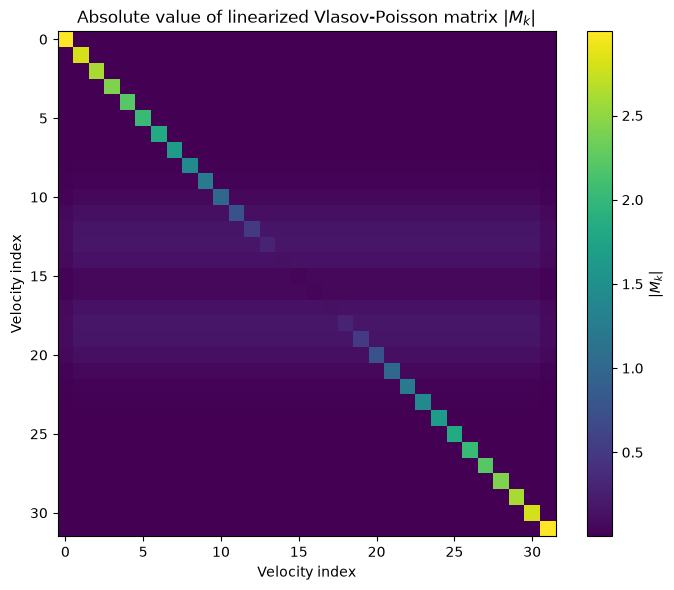

In [10]:
# ---------------------------------------------------------
# Visualize matrix magnitude
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    np.abs(M_k),
    aspect="auto"
)

fig.colorbar(
    im,
    ax=ax,
    label=r"$|M_k|$"
)

ax.set_xlabel("Velocity index")
ax.set_ylabel("Velocity index")
ax.set_title(
    r"Absolute value of linearized Vlasov-Poisson matrix $|M_k|$"
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "matrix_magnitude_Nv32_k0p5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
# ---------------------------------------------------------
# Basic matrix diagnostics
# ---------------------------------------------------------

matrix_norm = np.linalg.norm(M_k, ord=2)

hermiticity_error = np.linalg.norm(
    M_k - M_k.conj().T,
    ord=2
)

relative_hermiticity_error = (
    hermiticity_error / matrix_norm
)

print("Matrix 2-norm                :", matrix_norm)
print("Hermiticity error            :", hermiticity_error)
print("Relative Hermiticity error   :", relative_hermiticity_error)

Matrix 2-norm                : 3.184373477379818
Hermiticity error            : 6.012856402672417
Relative Hermiticity error   : 1.8882384385452005


In [12]:
# ---------------------------------------------------------
# Singular-value analysis
# ---------------------------------------------------------

singular_values = svdvals(M_k)

print("Largest singular value :", singular_values[0])
print("Smallest singular value:", singular_values[-1])
print("Condition number       :", singular_values[0] / singular_values[-1])

Largest singular value : 3.184373477379818
Smallest singular value: 0.0967741935483869
Condition number       : 32.905192599591516


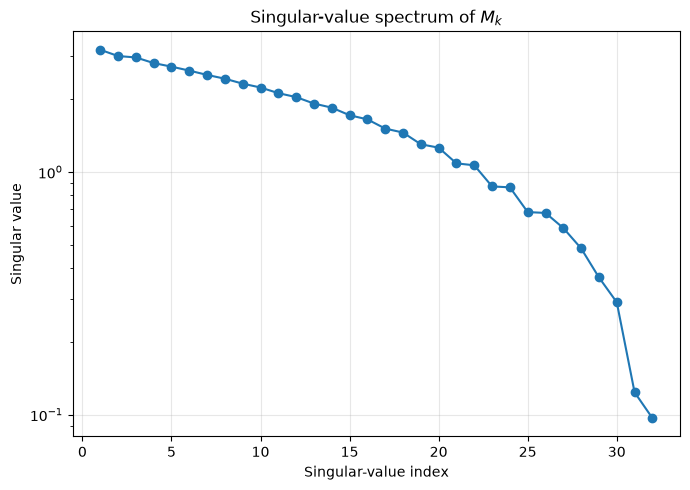

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogy(
    np.arange(1, Nv + 1),
    singular_values,
    "o-"
)

ax.set_xlabel("Singular-value index")
ax.set_ylabel("Singular value")
ax.set_title(r"Singular-value spectrum of $M_k$")
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "singular_values_Nv32_k0p5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# ---------------------------------------------------------
# Eigenvalue analysis
# ---------------------------------------------------------

eigenvalues = eigvals(M_k)

print("First 10 eigenvalues:\n")

for lam in eigenvalues[:10]:
    print(lam)

First 10 eigenvalues:

2.9999999874227212j
(-7.174588725437827e-16+2.8064513939870483j)
(6.921572080135878e-16+2.6129016007741046j)
(2.370935441982212e-16+2.419344576034605j)
(1.3434803255347288e-15+2.2257515195649193j)
(-1.4661761615618225e-15+2.0320102346769415j)
(-1.0832676609418695e-15+1.837773896787702j)
(2.2054894109771194e-15+1.6422220571528938j)
(-1.4839373326206382e-15+1.4439303011618057j)
(1.7524184406045949e-15+1.2411456504843683j)


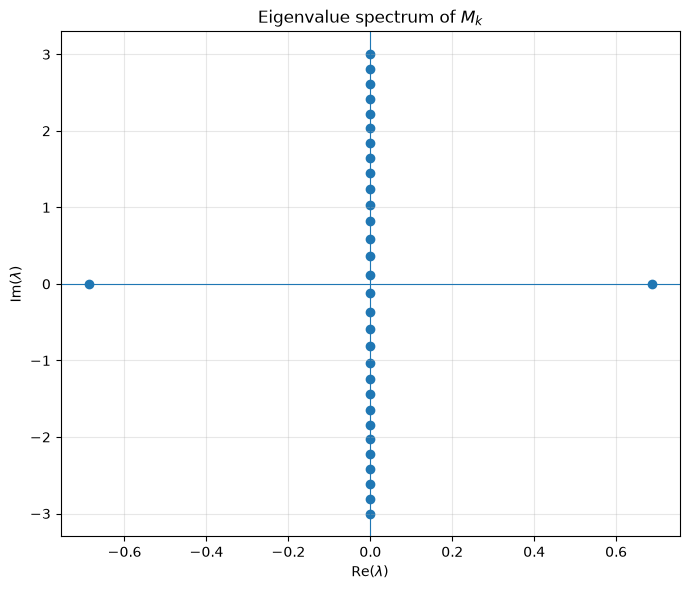

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    eigenvalues.real,
    eigenvalues.imag
)

ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)

ax.set_xlabel(r"$\mathrm{Re}(\lambda)$")
ax.set_ylabel(r"$\mathrm{Im}(\lambda)$")
ax.set_title(r"Eigenvalue spectrum of $M_k$")
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "eigenvalue_spectrum_Nv32_k0p5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
# ---------------------------------------------------------
# Construct implicit-Euler linear system
# ---------------------------------------------------------

dt = 0.01

I = np.eye(Nv)

A_k = I - dt * M_k

print("dt          :", dt)
print("A_k shape   :", A_k.shape)
print("A_k dtype   :", A_k.dtype)

dt          : 0.01
A_k shape   : (32, 32)
A_k dtype   : complex128


In [17]:
# ---------------------------------------------------------
# Conditioning and matrix diagnostics for A_k
# ---------------------------------------------------------

A_norm = np.linalg.norm(A_k, ord=2)

A_singular_values = svdvals(A_k)

A_sigma_max = A_singular_values[0]
A_sigma_min = A_singular_values[-1]

A_condition_number = A_sigma_max / A_sigma_min

A_hermiticity_error = np.linalg.norm(
    A_k - A_k.conj().T,
    ord=2
)

A_relative_hermiticity_error = (
    A_hermiticity_error / A_norm
)

print("A_k 2-norm                  :", A_norm)
print("Largest singular value      :", A_sigma_max)
print("Smallest singular value     :", A_sigma_min)
print("Condition number             :", A_condition_number)
print("Hermiticity error            :", A_hermiticity_error)
print("Relative Hermiticity error   :", A_relative_hermiticity_error)

A_k 2-norm                  : 1.0130208618785137
Largest singular value      : 1.0130208618785137
Smallest singular value     : 0.9872098091100471
Condition number             : 1.026145458169358
Hermiticity error            : 0.06012856402672419
Relative Hermiticity error   : 0.059355701634045015


In [18]:
# ---------------------------------------------------------
# Save singular values of A_k
# ---------------------------------------------------------

singular_data = np.column_stack([
    np.arange(1, Nv + 1),
    A_singular_values
])

np.savetxt(
    TABLE_DIR / f"singular_values_A_Nv{Nv}_k0p5_dt{dt:g}.csv",
    singular_data,
    delimiter=",",
    header="index,singular_value",
    comments=""
)

print("Saved singular values.")

Saved singular values.


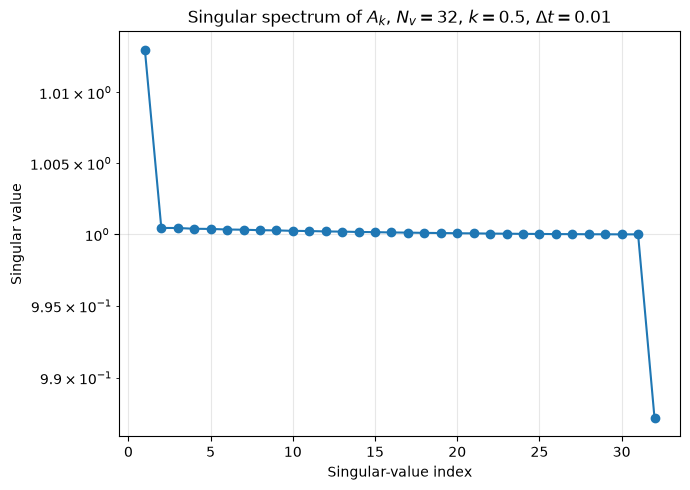

In [19]:
# ---------------------------------------------------------
# Singular-value spectrum of A_k
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogy(
    np.arange(1, Nv + 1),
    A_singular_values,
    "o-"
)

ax.set_xlabel("Singular-value index")
ax.set_ylabel("Singular value")
ax.set_title(
    rf"Singular spectrum of $A_k$, "
    rf"$N_v={Nv}$, $k={k}$, $\Delta t={dt}$"
)

ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR /
    f"singular_values_A_Nv{Nv}_k0p5_dt{dt:g}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# ---------------------------------------------------------
# Condition-number sweep over timestep
# ---------------------------------------------------------

dt_values = np.array([
    0.001,
    0.002,
    0.005,
    0.01,
    0.02,
    0.05,
    0.1,
    0.2,
    0.5,
    1.0,
])

dt_results = []

for dt_test in dt_values:

    A_test = np.eye(Nv) - dt_test * M_k

    s = svdvals(A_test)

    sigma_max = s[0]
    sigma_min = s[-1]

    condition_number = sigma_max / sigma_min

    dt_results.append([
        dt_test,
        sigma_max,
        sigma_min,
        condition_number
    ])

dt_results = np.array(dt_results)

print("dt        sigma_max        sigma_min        condition_number")

for row in dt_results:
    print(
        f"{row[0]:.4f}    "
        f"{row[1]:.8f}    "
        f"{row[2]:.8f}    "
        f"{row[3]:.8f}"
    )

dt        sigma_max        sigma_min        condition_number
0.0010    1.00129161    0.99871070    1.00258424
0.0020    1.00258553    0.99742370    1.00517516
0.0050    1.00648122    0.99357644    1.01298821
0.0100    1.01302086    0.98720981    1.02614546
0.0200    1.02627833    0.97464429    1.05297731
0.0500    1.06752817    0.93823541    1.13780418
0.1000    1.14152425    0.88148718    1.29499813
0.2000    1.31098229    0.78022651    1.68025858
0.5000    1.98359709    0.53805065    3.68663635
1.0000    3.39680143    0.22951740    14.79975544


In [21]:
# ---------------------------------------------------------
# Save timestep-conditioning data
# ---------------------------------------------------------

np.savetxt(
    TABLE_DIR / f"condition_vs_dt_Nv{Nv}_k0p5.csv",
    dt_results,
    delimiter=",",
    header="dt,sigma_max,sigma_min,condition_number",
    comments=""
)

print("Saved timestep-conditioning data.")

Saved timestep-conditioning data.


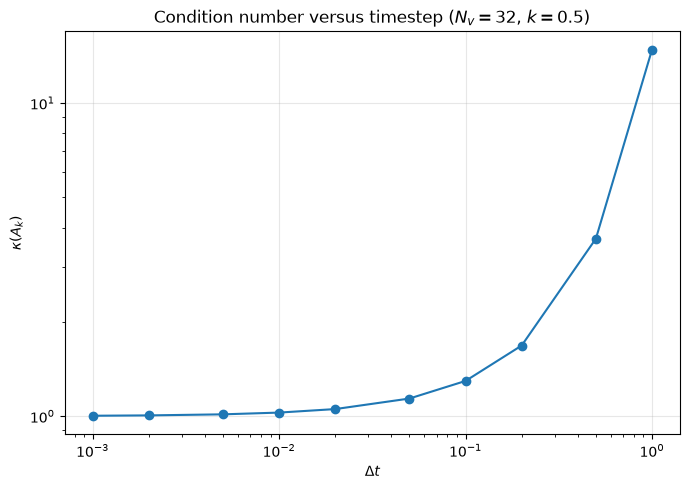

In [22]:
# ---------------------------------------------------------
# Condition number versus timestep
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

ax.loglog(
    dt_results[:, 0],
    dt_results[:, 3],
    "o-"
)

ax.set_xlabel(r"$\Delta t$")
ax.set_ylabel(r"$\kappa(A_k)$")
ax.set_title(
    rf"Condition number versus timestep "
    rf"($N_v={Nv}$, $k={k}$)"
)

ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / f"condition_vs_dt_Nv{Nv}_k0p5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

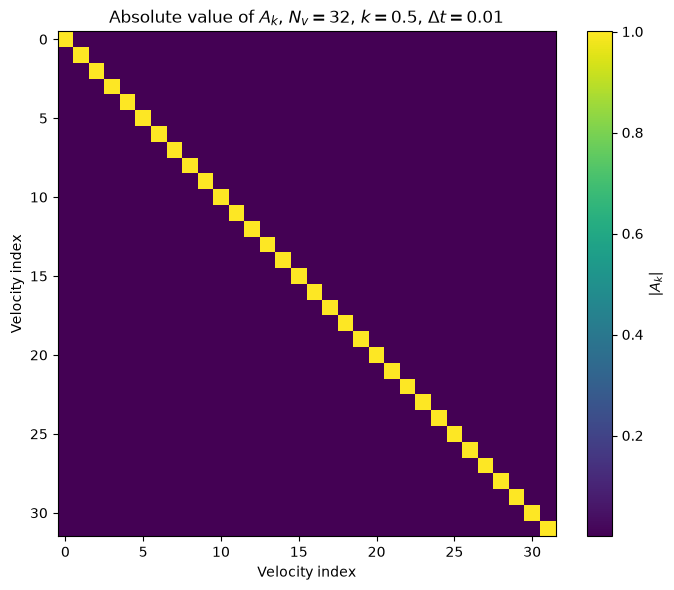

In [23]:
# ---------------------------------------------------------
# Visualize |A_k|
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    np.abs(A_k),
    aspect="auto"
)

fig.colorbar(
    im,
    ax=ax,
    label=r"$|A_k|$"
)

ax.set_xlabel("Velocity index")
ax.set_ylabel("Velocity index")
ax.set_title(
    rf"Absolute value of $A_k$, "
    rf"$N_v={Nv}$, $k={k}$, $\Delta t={dt}$"
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR /
    f"matrix_A_magnitude_Nv{Nv}_k0p5_dt{dt:g}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
# ---------------------------------------------------------
# Function to construct the linearized VP matrix
# ---------------------------------------------------------

def build_linearized_matrix(Nv, k, v_min=-6.0, v_max=6.0):
    """
    Construct the linearized Vlasov-Poisson matrix

        M_k = -i k V + (1 / i k) f0'(v) w^T

    using a uniform velocity grid and trapezoidal quadrature.
    """

    v = np.linspace(v_min, v_max, Nv)

    dv = (v_max - v_min) / (Nv - 1)

    f0 = (
        1.0 / np.sqrt(2.0 * np.pi)
        * np.exp(-v**2 / 2.0)
    )

    df0_dv = -v * f0

    # Trapezoidal quadrature weights
    w = np.full(Nv, dv)
    w[0] *= 0.5
    w[-1] *= 0.5

    V = np.diag(v)

    M = (
        -1j * k * V
        + (1.0 / (1j * k))
        * np.outer(df0_dv, w)
    )

    return v, M

In [25]:
# ---------------------------------------------------------
# Condition number versus velocity resolution
# ---------------------------------------------------------

k_test = 0.5
dt_test = 0.001

Nv_values = [8, 16, 32, 64, 128]

resolution_results = []

for Nv_test in Nv_values:

    v_test, M_test = build_linearized_matrix(
        Nv=Nv_test,
        k=k_test
    )

    A_test = (
        np.eye(Nv_test)
        - dt_test * M_test
    )

    s = svdvals(A_test)

    sigma_max = s[0]
    sigma_min = s[-1]

    condition_number = sigma_max / sigma_min

    resolution_results.append([
        Nv_test,
        Nv_test,
        sigma_max,
        sigma_min,
        condition_number
    ])

resolution_results = np.array(
    resolution_results
)

print(
    "Nv      DOF      sigma_max      "
    "sigma_min      condition_number"
)

for row in resolution_results:

    print(
        f"{int(row[0]):<7}"
        f"{int(row[1]):<9}"
        f"{row[2]:<15.8f}"
        f"{row[3]:<15.8f}"
        f"{row[4]:.8f}"
    )

Nv      DOF      sigma_max      sigma_min      condition_number
8      8        1.00148345     0.99851917     1.00296868
16     16       1.00128025     0.99872199     1.00256153
32     32       1.00129161     0.99871070     1.00258424
64     64       1.00129699     0.99870536     1.00259499
128    128      1.00129961     0.99870276     1.00260022


In [26]:
# ---------------------------------------------------------
# Save resolution-conditioning data
# ---------------------------------------------------------

np.savetxt(
    TABLE_DIR / f"condition_vs_Nv_k0p5_dt{dt_test:g}.csv",
    resolution_results,
    delimiter=",",
    header=(
        "Nv,DOF,sigma_max,"
        "sigma_min,condition_number"
    ),
    comments=""
)

print("Saved resolution-conditioning data.")

Saved resolution-conditioning data.


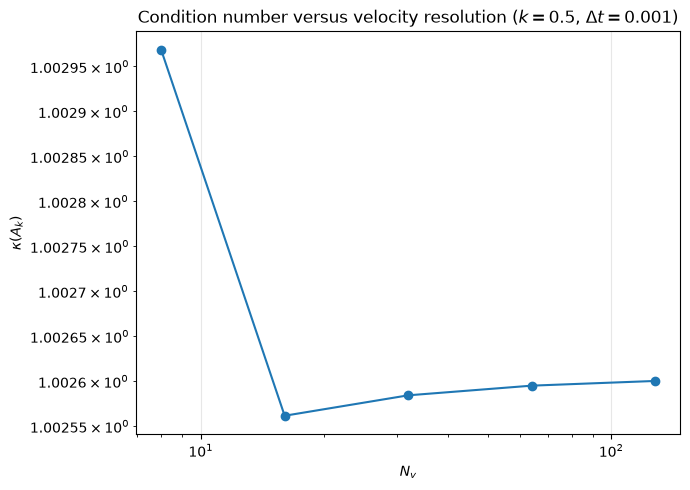

In [27]:
# ---------------------------------------------------------
# Condition number versus velocity resolution
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

ax.loglog(
    resolution_results[:, 0],
    resolution_results[:, 4],
    "o-"
)

ax.set_xlabel(r"$N_v$")
ax.set_ylabel(r"$\kappa(A_k)$")

ax.set_title(
    rf"Condition number versus velocity resolution "
    rf"($k={k_test}$, $\Delta t={dt_test}$)"
)

ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR /
    f"condition_vs_Nv_k0p5_dt{dt_test:g}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
import json

resolution_summary = {
    "experiment": "linearized_vlasov_poisson_conditioning",
    "wavenumber_k": float(k_test),
    "timestep_dt": float(dt_test),
    "velocity_domain": [-6.0, 6.0],
    "quadrature": "trapezoidal",
    "results": [
        {
            "Nv": int(row[0]),
            "dimension": int(row[1]),
            "sigma_max": float(row[2]),
            "sigma_min": float(row[3]),
            "condition_number": float(row[4]),
        }
        for row in resolution_results
    ],
}

summary_path = (
    TABLE_DIR / "condition_vs_Nv_k0p5_dt0p001_summary.json"
)

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(resolution_summary, file, indent=2)

print("Saved:", summary_path.resolve())

Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\matrix_analysis\condition_vs_Nv_k0p5_dt0p001_summary.json


In [29]:
# ---------------------------------------------------------
# Condition number versus wavenumber
# ---------------------------------------------------------

Nv_test = 32
dt_test = 0.001

k_values = np.array([0.1, 0.2, 0.5, 1.0, 2.0])

k_results = []

for k_test in k_values:

    v_test, M_test = build_linearized_matrix(
        Nv=Nv_test,
        k=k_test
    )

    A_test = np.eye(Nv_test) - dt_test * M_test

    s = svdvals(A_test)

    sigma_max = s[0]
    sigma_min = s[-1]
    condition_number = sigma_max / sigma_min

    k_results.append([
        k_test,
        Nv_test,
        dt_test,
        sigma_max,
        sigma_min,
        condition_number
    ])

k_results = np.array(k_results)

print("k       sigma_max      sigma_min      condition_number")

for row in k_results:
    print(
        f"{row[0]:<7.2f}"
        f"{row[3]:<15.8f}"
        f"{row[4]:<15.8f}"
        f"{row[5]:.8f}"
    )

k       sigma_max      sigma_min      condition_number
0.10   1.00647261     0.99356808     1.01298807
0.20   1.00323097     0.99677870     1.00647312
0.50   1.00129161     0.99871070     1.00258424
1.00   1.00064825     0.99935774     1.00129134
2.00   1.00033623     0.99968928     1.00064715


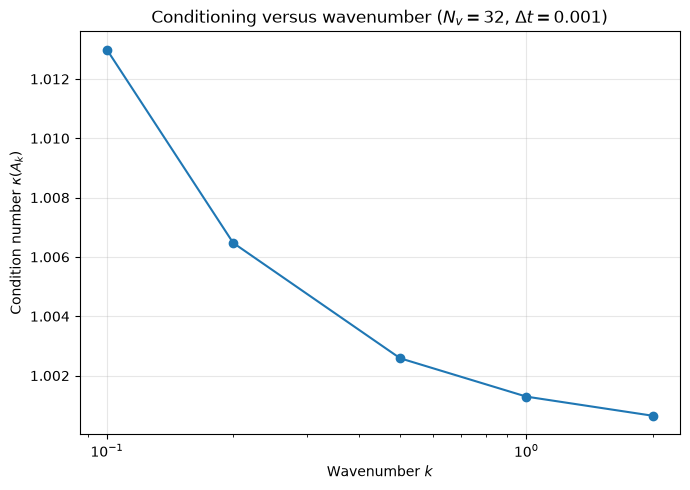

In [30]:
# Save raw numerical data
np.savetxt(
    TABLE_DIR / "condition_vs_k_Nv32_dt0p001.csv",
    k_results,
    delimiter=",",
    header="k,Nv,dt,sigma_max,sigma_min,condition_number",
    comments=""
)

# Plot condition number versus wavenumber
fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogx(
    k_results[:, 0],
    k_results[:, 5],
    "o-"
)

ax.set_xlabel(r"Wavenumber $k$")
ax.set_ylabel(r"Condition number $\kappa(A_k)$")
ax.set_title(
    rf"Conditioning versus wavenumber "
    rf"($N_v={Nv_test}$, $\Delta t={dt_test}$)"
)

ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "condition_vs_k_Nv32_dt0p001.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
# ---------------------------------------------------------
# Extended wavenumber conditioning sweep
# ---------------------------------------------------------

Nv_test = 32
dt_test = 0.001

k_values = np.array([
    0.02,
    0.05,
    0.1,
    0.2,
    0.5,
    1.0,
    2.0,
])

k_results = []

for k_test in k_values:

    v_test, M_test = build_linearized_matrix(
        Nv=Nv_test,
        k=k_test
    )

    A_test = (
        np.eye(Nv_test)
        - dt_test * M_test
    )

    s = svdvals(A_test)

    sigma_max = s[0]
    sigma_min = s[-1]

    condition_number = sigma_max / sigma_min

    k_results.append([
        k_test,
        Nv_test,
        dt_test,
        sigma_max,
        sigma_min,
        condition_number
    ])

k_results = np.array(k_results)

print(
    "k       sigma_max      "
    "sigma_min      condition_number"
)

for row in k_results:

    print(
        f"{row[0]:<7.2f}"
        f"{row[3]:<15.8f}"
        f"{row[4]:<15.8f}"
        f"{row[5]:.8f}"
    )

k       sigma_max      sigma_min      condition_number
0.02   1.03278109     0.96825843     1.06663785
0.05   1.01298730     0.98717824     1.02614428
0.10   1.00647261     0.99356808     1.01298807
0.20   1.00323097     0.99677870     1.00647312
0.50   1.00129161     0.99871070     1.00258424
1.00   1.00064825     0.99935774     1.00129134
2.00   1.00033623     0.99968928     1.00064715


In [32]:
# ---------------------------------------------------------
# Save extended k sweep
# ---------------------------------------------------------

np.savetxt(
    TABLE_DIR / "condition_vs_k_extended_Nv32_dt0p001.csv",
    k_results,
    delimiter=",",
    header=(
        "k,Nv,dt,sigma_max,"
        "sigma_min,condition_number"
    ),
    comments=""
)

print("Saved extended k-sweep data.")

Saved extended k-sweep data.


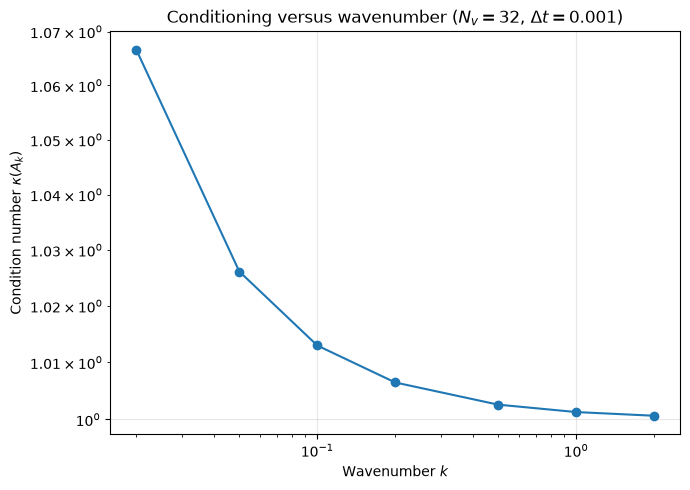

In [33]:
# ---------------------------------------------------------
# Extended k-conditioning plot
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

ax.loglog(
    k_results[:, 0],
    k_results[:, 5],
    "o-"
)

ax.set_xlabel(r"Wavenumber $k$")
ax.set_ylabel(r"Condition number $\kappa(A_k)$")

ax.set_title(
    rf"Conditioning versus wavenumber "
    rf"($N_v={Nv_test}$, $\Delta t={dt_test}$)"
)

ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR /
    "condition_vs_k_extended_Nv32_dt0p001.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
# ---------------------------------------------------------
# Test empirical 1/k conditioning scaling
# ---------------------------------------------------------

inv_k = 1.0 / k_results[:, 0]

kappa_minus_one = k_results[:, 5] - 1.0

# Linear fit:
# kappa - 1 = C / k + intercept
fit_coefficients = np.polyfit(
    inv_k,
    kappa_minus_one,
    deg=1
)

C_fit = fit_coefficients[0]
intercept_fit = fit_coefficients[1]

predicted = (
    C_fit * inv_k
    + intercept_fit
)

residuals = (
    kappa_minus_one
    - predicted
)

ss_res = np.sum(residuals**2)
ss_tot = np.sum(
    (kappa_minus_one - np.mean(kappa_minus_one))**2
)

r_squared_scaling = 1.0 - ss_res / ss_tot

print("Empirical scaling:")
print()
print("kappa(A_k) - 1 ≈ C/k + intercept")
print()
print("C         =", C_fit)
print("intercept =", intercept_fit)
print("R²        =", r_squared_scaling)

Empirical scaling:

kappa(A_k) - 1 ≈ C/k + intercept

C         = 0.001332849387873762
intercept = -0.00017016210581078045
R²        = 0.9999348132498791


In [35]:
# ---------------------------------------------------------
# Save empirical scaling analysis
# ---------------------------------------------------------

scaling_data = np.column_stack([
    k_results[:, 0],
    inv_k,
    kappa_minus_one,
    predicted,
    residuals
])

np.savetxt(
    TABLE_DIR / "kappa_scaling_vs_inverse_k.csv",
    scaling_data,
    delimiter=",",
    header=(
        "k,1_over_k,kappa_minus_1,"
        "fitted_value,residual"
    ),
    comments=""
)

print("Saved inverse-k scaling analysis.")

Saved inverse-k scaling analysis.


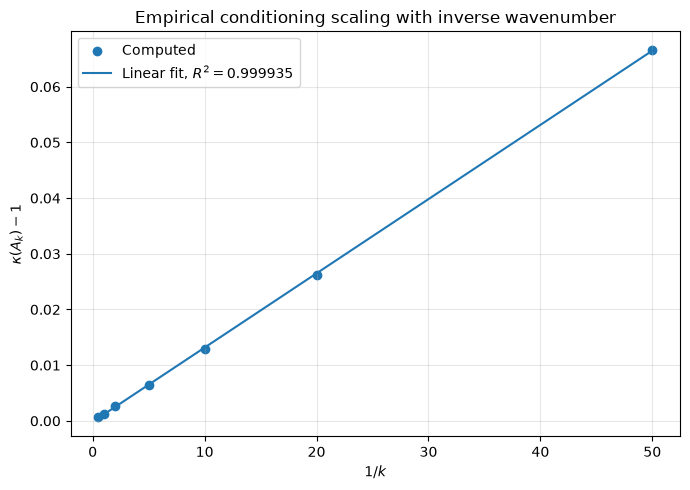

In [36]:
# ---------------------------------------------------------
# Plot kappa - 1 versus 1/k
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    inv_k,
    kappa_minus_one,
    label="Computed"
)

sort_indices = np.argsort(inv_k)

ax.plot(
    inv_k[sort_indices],
    predicted[sort_indices],
    label=rf"Linear fit, $R^2={r_squared_scaling:.6f}$"
)

ax.set_xlabel(r"$1/k$")
ax.set_ylabel(r"$\kappa(A_k)-1$")
ax.set_title(
    r"Empirical conditioning scaling with inverse wavenumber"
)

ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "kappa_minus_one_vs_inverse_k.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
# ---------------------------------------------------------
# Hermitian embedding of A_k
# ---------------------------------------------------------

dt_embed = 0.001

A_embed = (
    np.eye(Nv)
    - dt_embed * M_k
)

H_embed = np.block([
    [
        np.zeros_like(A_embed),
        A_embed
    ],
    [
        A_embed.conj().T,
        np.zeros_like(A_embed)
    ]
])

print("A_k dimension       :", A_embed.shape)
print("H_A dimension       :", H_embed.shape)

A_k dimension       : (32, 32)
H_A dimension       : (64, 64)


In [38]:
# ---------------------------------------------------------
# Verify Hermiticity of embedded matrix
# ---------------------------------------------------------

H_norm = np.linalg.norm(H_embed, ord=2)

H_hermiticity_error = np.linalg.norm(
    H_embed - H_embed.conj().T,
    ord=2
)

relative_H_error = (
    H_hermiticity_error / H_norm
)

print("H_A norm                    :", H_norm)
print("H_A Hermiticity error       :", H_hermiticity_error)
print("Relative Hermiticity error  :", relative_H_error)

H_A norm                    : 1.001291607496028
H_A Hermiticity error       : 0.0
Relative Hermiticity error  : 0.0


In [39]:
# ---------------------------------------------------------
# Compare conditioning of A_k and Hermitian embedding
# ---------------------------------------------------------

A_s = svdvals(A_embed)
H_s = svdvals(H_embed)

A_condition = A_s[0] / A_s[-1]
H_condition = H_s[0] / H_s[-1]

print("Condition number of A_k :", A_condition)
print("Condition number of H_A :", H_condition)

Condition number of A_k : 1.0025842400932719
Condition number of H_A : 1.0025842400932719


In [40]:
# ---------------------------------------------------------
# Structural analysis of M_k and A_k
# ---------------------------------------------------------

Nv_struct = 32
k_struct = 0.5
dt_struct = 0.001

v_struct, M_struct = build_linearized_matrix(
    Nv=Nv_struct,
    k=k_struct
)

A_struct = (
    np.eye(Nv_struct)
    - dt_struct * M_struct
)

# Numerical rank tolerance
rank_tolerance = 1e-12

rank_M = np.linalg.matrix_rank(
    M_struct,
    tol=rank_tolerance
)

rank_A = np.linalg.matrix_rank(
    A_struct,
    tol=rank_tolerance
)

# Number of numerically nonzero entries
M_nonzero = np.count_nonzero(
    np.abs(M_struct) > rank_tolerance
)

A_nonzero = np.count_nonzero(
    np.abs(A_struct) > rank_tolerance
)

M_total = M_struct.size
A_total = A_struct.size

M_density = M_nonzero / M_total
A_density = A_nonzero / A_total

print("M_k")
print("------------------------------")
print("Dimension          :", M_struct.shape)
print("Numerical rank     :", rank_M)
print("Nonzero entries    :", M_nonzero)
print("Total entries      :", M_total)
print("Density            :", M_density)

print()

print("A_k")
print("------------------------------")
print("Dimension          :", A_struct.shape)
print("Numerical rank     :", rank_A)
print("Nonzero entries    :", A_nonzero)
print("Total entries      :", A_total)
print("Density            :", A_density)

M_k
------------------------------
Dimension          : (32, 32)
Numerical rank     : 32
Nonzero entries    : 1024
Total entries      : 1024
Density            : 1.0

A_k
------------------------------
Dimension          : (32, 32)
Numerical rank     : 32
Nonzero entries    : 1024
Total entries      : 1024
Density            : 1.0


In [41]:
# ---------------------------------------------------------
# Verify diagonal + rank-1 structure
# ---------------------------------------------------------

v_test, M_test = build_linearized_matrix(
    Nv=32,
    k=0.5
)

dv_test = (
    (6.0 - (-6.0))
    / (32 - 1)
)

f0_test = (
    1.0 / np.sqrt(2.0 * np.pi)
    * np.exp(-v_test**2 / 2.0)
)

df0_test = -v_test * f0_test

w_test = np.full(32, dv_test)
w_test[0] *= 0.5
w_test[-1] *= 0.5

D_test = -1j * 0.5 * np.diag(v_test)

R_test = (
    (1.0 / (1j * 0.5))
    * np.outer(df0_test, w_test)
)

M_reconstructed = D_test + R_test

reconstruction_error = np.linalg.norm(
    M_test - M_reconstructed
)

rank_R = np.linalg.matrix_rank(
    R_test,
    tol=1e-12
)

print("Rank of correction R :", rank_R)
print("Reconstruction error  :", reconstruction_error)

Rank of correction R : 1
Reconstruction error  : 0.0


In [42]:
# ---------------------------------------------------------
# Quantum resource scaling
# ---------------------------------------------------------

k_resource = 0.5
dt_resource = 0.001

Nv_values = [8, 16, 32, 64, 128]

resource_results = []

for Nv_test in Nv_values:

    v_test, M_test = build_linearized_matrix(
        Nv=Nv_test,
        k=k_resource
    )

    A_test = (
        np.eye(Nv_test)
        - dt_resource * M_test
    )

    # Hermitian embedding
    H_test = np.block([
        [
            np.zeros_like(A_test),
            A_test
        ],
        [
            A_test.conj().T,
            np.zeros_like(A_test)
        ]
    ])

    # Conditioning
    singular_values = svdvals(A_test)

    condition_number = (
        singular_values[0]
        / singular_values[-1]
    )

    # Matrix density
    nonzero = np.count_nonzero(
        np.abs(M_test) > 1e-12
    )

    density = (
        nonzero / M_test.size
    )

    # Quantum state dimension
    H_dimension = H_test.shape[0]

    n_qubits = int(
        np.ceil(np.log2(H_dimension))
    )

    # Rank of M
    rank_M = np.linalg.matrix_rank(
        M_test,
        tol=1e-12
    )

    resource_results.append([
        Nv_test,
        M_test.shape[0],
        H_dimension,
        n_qubits,
        rank_M,
        density,
        condition_number
    ])

resource_results = np.array(
    resource_results
)

print(
    "Nv    A_dim    H_dim    "
    "qubits    rank(M)    density    kappa(A)"
)

for row in resource_results:

    print(
        f"{int(row[0]):<6}"
        f"{int(row[1]):<9}"
        f"{int(row[2]):<9}"
        f"{int(row[3]):<10}"
        f"{int(row[4]):<11}"
        f"{row[5]:<11.4f}"
        f"{row[6]:.8f}"
    )

Nv    A_dim    H_dim    qubits    rank(M)    density    kappa(A)
8     8        16       4         8          1.0000     1.00296868
16    16       32       5         16         1.0000     1.00256153
32    32       64       6         32         1.0000     1.00258424
64    64       128      7         64         1.0000     1.00259499
128   128      256      8         128        1.0000     1.00260022


In [43]:
# ---------------------------------------------------------
# Save quantum resource scaling
# ---------------------------------------------------------

np.savetxt(
    TABLE_DIR / "quantum_resource_scaling.csv",
    resource_results,
    delimiter=",",
    header=(
        "Nv,A_dimension,H_dimension,"
        "state_qubits,rank_M,density,"
        "condition_number"
    ),
    comments=""
)

print("Saved quantum resource scaling.")

Saved quantum resource scaling.


In [44]:
# ---------------------------------------------------------
# Timestep / conditioning trade-off
# ---------------------------------------------------------

T_final = 20.0

dt_values = np.array([
    0.001,
    0.002,
    0.005,
    0.01,
    0.02,
    0.05,
    0.1,
    0.2,
    0.5,
    1.0,
])

tradeoff_results = []

for dt_test in dt_values:

    A_test = (
        np.eye(32)
        - dt_test * M_k
    )

    s = svdvals(A_test)

    condition_number = (
        s[0] / s[-1]
    )

    n_steps = T_final / dt_test

    cost_proxy = (
        n_steps * condition_number
    )

    tradeoff_results.append([
        dt_test,
        n_steps,
        condition_number,
        cost_proxy
    ])

tradeoff_results = np.array(
    tradeoff_results
)

print(
    "dt       N_steps       kappa(A)       "
    "N_steps * kappa"
)

for row in tradeoff_results:

    print(
        f"{row[0]:<9.4f}"
        f"{row[1]:<14.1f}"
        f"{row[2]:<15.8f}"
        f"{row[3]:.4f}"
    )

dt       N_steps       kappa(A)       N_steps * kappa
0.0010   20000.0       1.00258424     20051.6848
0.0020   10000.0       1.00517516     10051.7516
0.0050   4000.0        1.01298821     4051.9528
0.0100   2000.0        1.02614546     2052.2909
0.0200   1000.0        1.05297731     1052.9773
0.0500   400.0         1.13780418     455.1217
0.1000   200.0         1.29499813     258.9996
0.2000   100.0         1.68025858     168.0259
0.5000   40.0          3.68663635     147.4655
1.0000   20.0          14.79975544    295.9951


In [45]:
np.savetxt(
    TABLE_DIR / "timestep_conditioning_tradeoff.csv",
    tradeoff_results,
    delimiter=",",
    header="dt,N_steps,condition_number,cost_proxy",
    comments=""
)

print("Saved timestep-conditioning trade-off.")

Saved timestep-conditioning trade-off.


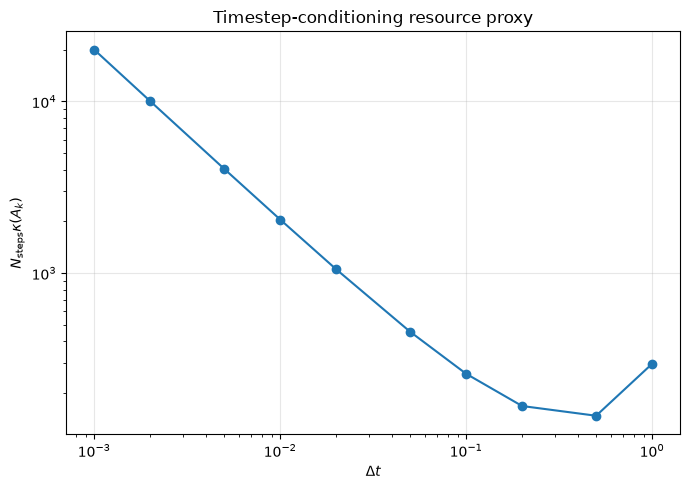

In [46]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.loglog(
    tradeoff_results[:, 0],
    tradeoff_results[:, 3],
    "o-"
)

ax.set_xlabel(r"$\Delta t$")
ax.set_ylabel(
    r"$N_{\mathrm{steps}}\kappa(A_k)$"
)

ax.set_title(
    "Timestep-conditioning resource proxy"
)

ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR /
    "timestep_conditioning_resource_proxy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()